# Decision Tree Classification

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_style("whitegrid")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
os.makedirs("figures", exist_ok=True)

SEED = 42

## 1. Split Quality: Worked Example

In [2]:
# Gini = 1 - sum(p^2); entropy = -sum(p * log2 p); gain = parent impurity - weighted child impurity
def gini(counts):
    p = np.array(counts) / np.sum(counts)
    return 1 - np.sum(p ** 2)

def entropy(counts):
    p = np.array(counts) / np.sum(counts)
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p))) + 0.0

def gain(measure, parent, children):
    n = sum(sum(c) for c in children)
    weighted = sum(sum(c) / n * measure(c) for c in children)
    return measure(parent) - weighted

parent = [5, 5]                                   # [attack, benign]
splits = {
    "Split A": [[5, 1], [0, 4]],                  # left: 5 attack, 1 benign; right: 0 attack, 4 benign
    "Split B": [[3, 2], [2, 3]],
}

rows = [{"Split": "Parent node", "Gini": gini(parent), "Entropy": entropy(parent),
         "Gini gain": np.nan, "Information gain (entropy)": np.nan}]
for name, ch in splits.items():
    n = sum(sum(c) for c in ch)
    rows.append({"Split": name,
                 "Gini": sum(sum(c) / n * gini(c) for c in ch),
                 "Entropy": sum(sum(c) / n * entropy(c) for c in ch),
                 "Gini gain": gain(gini, parent, ch),
                 "Information gain (entropy)": gain(entropy, parent, ch)})

example = pd.DataFrame(rows).set_index("Split")
example.round(3)

,Gini,Entropy,Gini gain,Information gain (entropy)
Split,,,,
Parent node,0.500,1.000,NaN,NaN
Split A,0.167,0.390,0.333,0.610
Split B,0.480,0.971,0.020,0.029


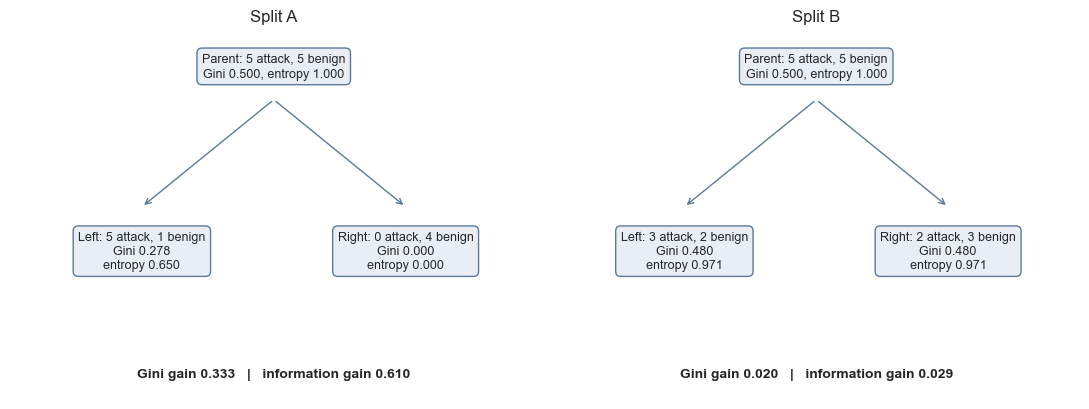

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (name, ch) in zip(axes, splits.items()):
    ax.axis("off")
    ax.set_xlim(0, 10); ax.set_ylim(0, 10)
    box = dict(boxstyle="round,pad=0.4", fc="#e9eef5", ec="#5b7a99")
    ax.text(5, 9, "Parent: 5 attack, 5 benign\nGini 0.500, entropy 1.000", ha="center", va="center", bbox=box, fontsize=9)
    labels = ["Left", "Right"]
    for x, c, side in zip([2.5, 7.5], ch, labels):
        ax.annotate("", xy=(x, 5.2), xytext=(5, 8.1), arrowprops=dict(arrowstyle="->", color="#5b7a99"))
        ax.text(x, 4, f"{side}: {c[0]} attack, {c[1]} benign\nGini {gini(c):.3f}\nentropy {entropy(c):.3f}",
                ha="center", va="center", bbox=box, fontsize=9)
    ax.text(5, 0.6, f"Gini gain {gain(gini, parent, ch):.3f}   |   information gain {gain(entropy, parent, ch):.3f}",
            ha="center", fontsize=10, weight="bold")
    ax.set_title(name)
plt.tight_layout()
plt.savefig("figures/dt-01-split-example.png", dpi=160, bbox_inches="tight")
plt.show()

## 2. Load the Training and Testing Sets

In [4]:
train = pd.read_csv("train_set.csv")
test = pd.read_csv("test_set.csv")

X_train, y_train = train.drop(columns="Label"), train["Label"]
X_test, y_test = test.drop(columns="Label"), test["Label"]
classes = sorted(y_train.unique())
features = list(X_train.columns)

print(f"Training set: {X_train.shape[0]:,} flows, {X_train.shape[1]} features")
print(f"Testing set:  {X_test.shape[0]:,} flows")

Training set: 7,508 flows, 65 features
Testing set:  3,218 flows


## 3. Choosing the Tree Depth

Maximum depth is selected by 5-fold cross-validation on the training set. The simplest setting within 0.003 of the highest cross-validated accuracy is used.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
depths = list(range(1, 21))

sweep = []
for crit in ["gini", "entropy"]:
    for d in depths:
        tree = DecisionTreeClassifier(criterion=crit, max_depth=d, random_state=SEED)
        cv_acc = cross_val_score(tree, X_train, y_train, cv=cv).mean()
        train_acc = tree.fit(X_train, y_train).score(X_train, y_train)
        sweep.append({"criterion": crit, "max_depth": d, "train": train_acc, "cv": cv_acc})
sweep = pd.DataFrame(sweep)

top_cv = sweep["cv"].max()
print(f"Highest cross-validated accuracy: {top_cv:.3f}")

# Simplest tree whose cross-validated accuracy is within 0.003 of the highest
close = sweep[sweep["cv"] >= top_cv - 0.003].sort_values(["max_depth", "cv"], ascending=[True, False])
best = close.iloc[0]
print(f"Selected: criterion = {best['criterion']}, max_depth = {int(best['max_depth'])} "
      f"(cross-validated accuracy {best['cv']:.3f})")
sweep.pivot(index="max_depth", columns="criterion", values="cv").round(3).T

Highest cross-validated accuracy: 0.927
Selected: criterion = entropy, max_depth = 9 (cross-validated accuracy 0.925)


max_depth,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
criterion,,,,,,,,,,,,,,,,,,,,
entropy,0.186,0.328,0.560,0.688,0.817,0.867,0.903,0.919,0.925,0.926,0.927,0.927,0.926,0.925,0.927,0.926,0.925,0.926,0.925,0.926
gini,0.177,0.275,0.405,0.546,0.672,0.775,0.840,0.880,0.894,0.913,0.922,0.922,0.923,0.923,0.924,0.921,0.921,0.923,0.924,0.924


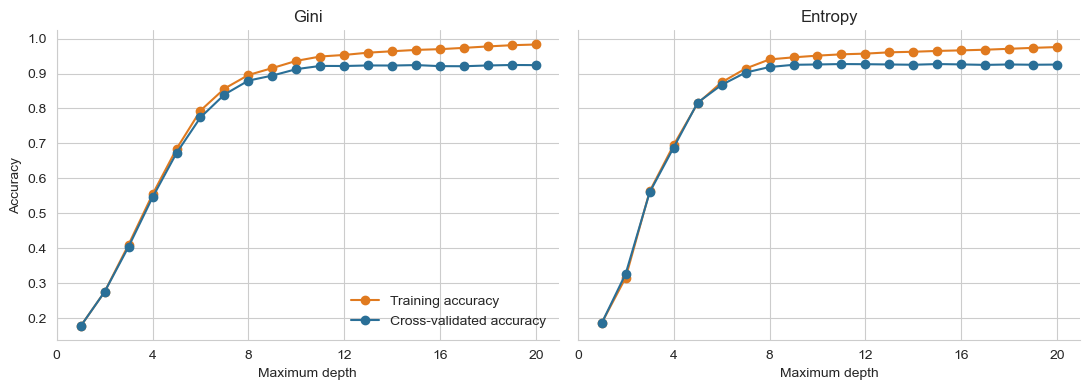

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, crit in zip(axes, ["gini", "entropy"]):
    s = sweep[sweep["criterion"] == crit]
    ax.plot(s["max_depth"], s["train"], marker="o", color="#e07a1f", label="Training accuracy")
    ax.plot(s["max_depth"], s["cv"], marker="o", color="#2a6f97", label="Cross-validated accuracy")
    ax.set_title(crit.capitalize())
    ax.set_xlabel("Maximum depth")
    ax.set_xticks(range(0, 21, 4))
axes[0].set_ylabel("Accuracy")
axes[0].legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig("figures/dt-02-depth-sweep.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Three Trees

In [7]:
tree_a = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=SEED).fit(X_train, y_train)
tree_b = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=SEED).fit(X_train, y_train)
tree_c = DecisionTreeClassifier(criterion=best["criterion"], max_depth=int(best["max_depth"]),
                                random_state=SEED).fit(X_train, y_train)

trees = {"A: Gini, depth 3": tree_a, "B: Entropy, depth 3": tree_b,
         f"C: {best['criterion'].capitalize()}, depth {int(best['max_depth'])}": tree_c}

summary = pd.DataFrame({
    name: {"Depth": t.get_depth(), "Leaves": t.get_n_leaves(),
           "Training accuracy": t.score(X_train, y_train),
           "Testing accuracy": t.score(X_test, y_test)}
    for name, t in trees.items()
}).T
summary.round(3)

,Depth,Leaves,Training accuracy,Testing accuracy
"A: Gini, depth 3",3.0,8.0,0.411,0.409
"B: Entropy, depth 3",3.0,8.0,0.563,0.564
"C: Entropy, depth 9",9.0,124.0,0.946,0.925


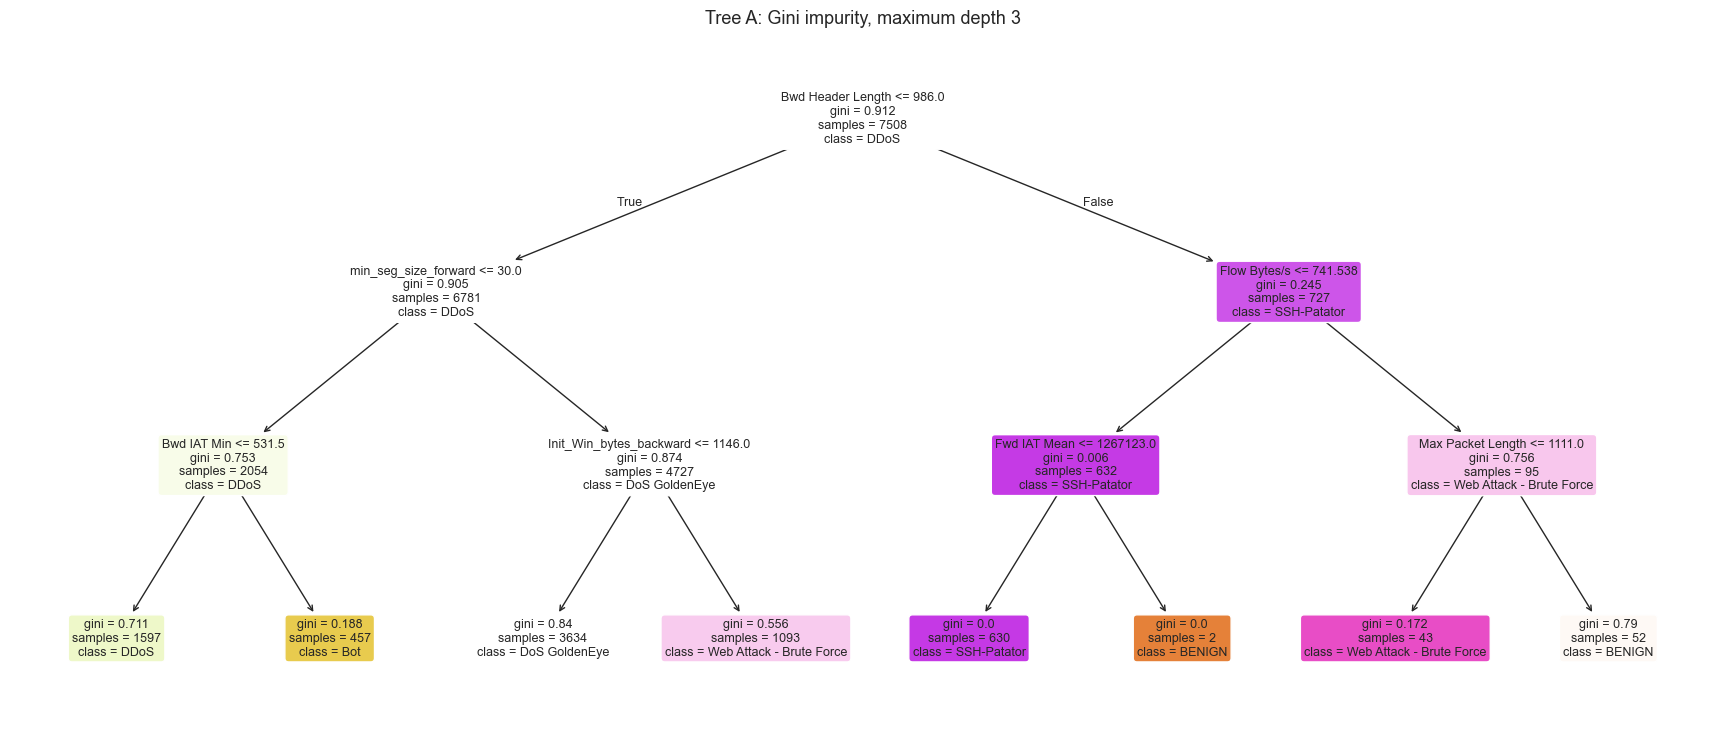

In [8]:
def draw_tree(tree, title, path, max_depth=None, size=(22, 9)):
    fig, ax = plt.subplots(figsize=size)
    nodes = plot_tree(tree, feature_names=features, class_names=list(tree.classes_), filled=True,
                      rounded=True, impurity=True, max_depth=max_depth, fontsize=9, ax=ax)
    for node in nodes:
        # Drop the long per-class count vector so each box stays readable
        node.set_text(re.sub(r"value = \[.*?\]\n", "", node.get_text(), flags=re.S))
    ax.set_title(title, fontsize=13)
    plt.savefig(path, dpi=140, bbox_inches="tight")
    plt.show()

draw_tree(tree_a, "Tree A: Gini impurity, maximum depth 3", "figures/dt-03-tree-gini-depth3.png")

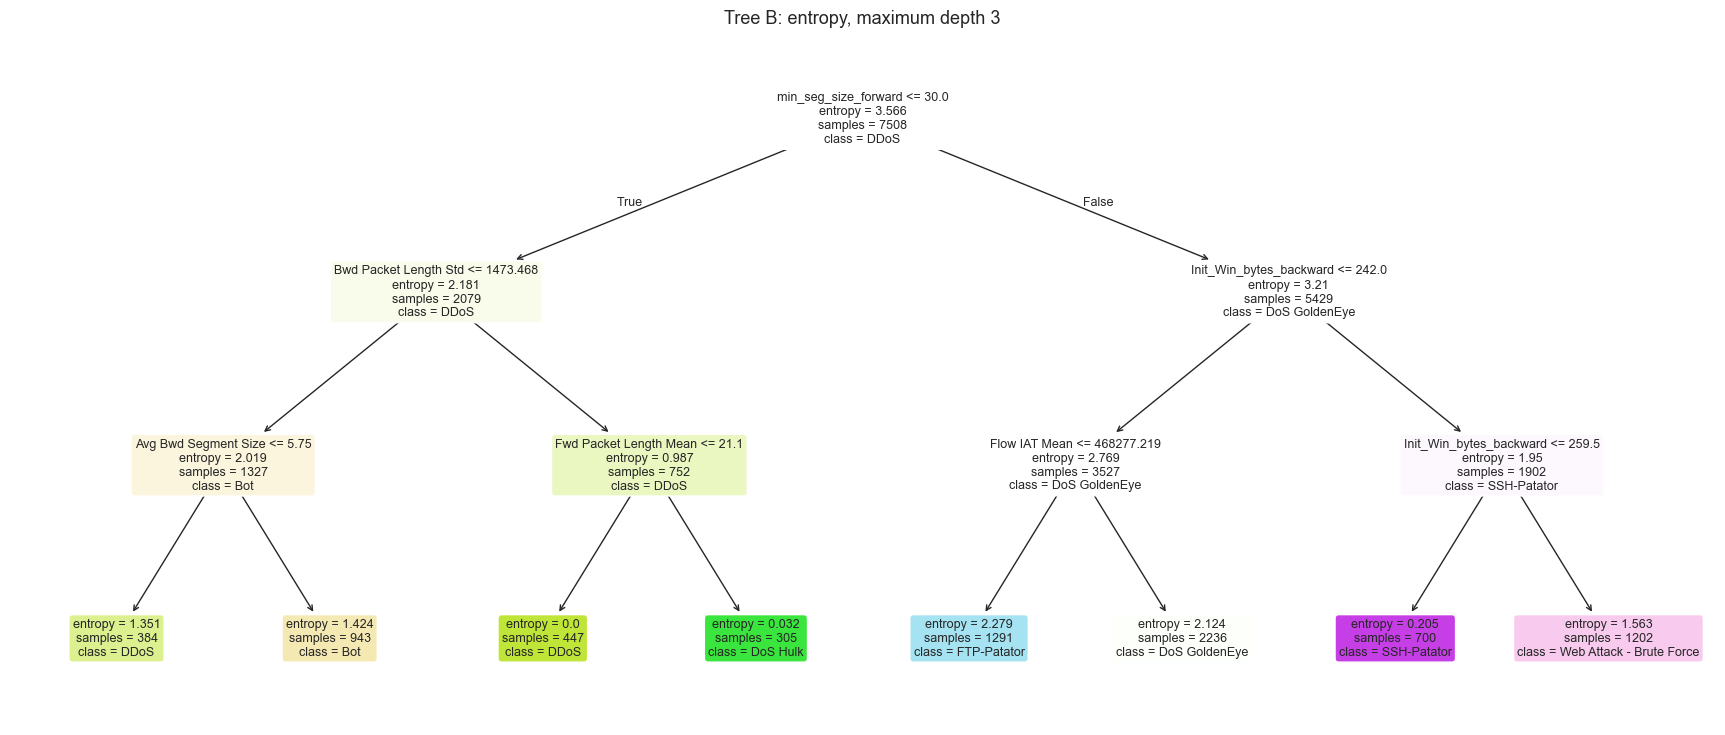

In [9]:
draw_tree(tree_b, "Tree B: entropy, maximum depth 3", "figures/dt-04-tree-entropy-depth3.png")

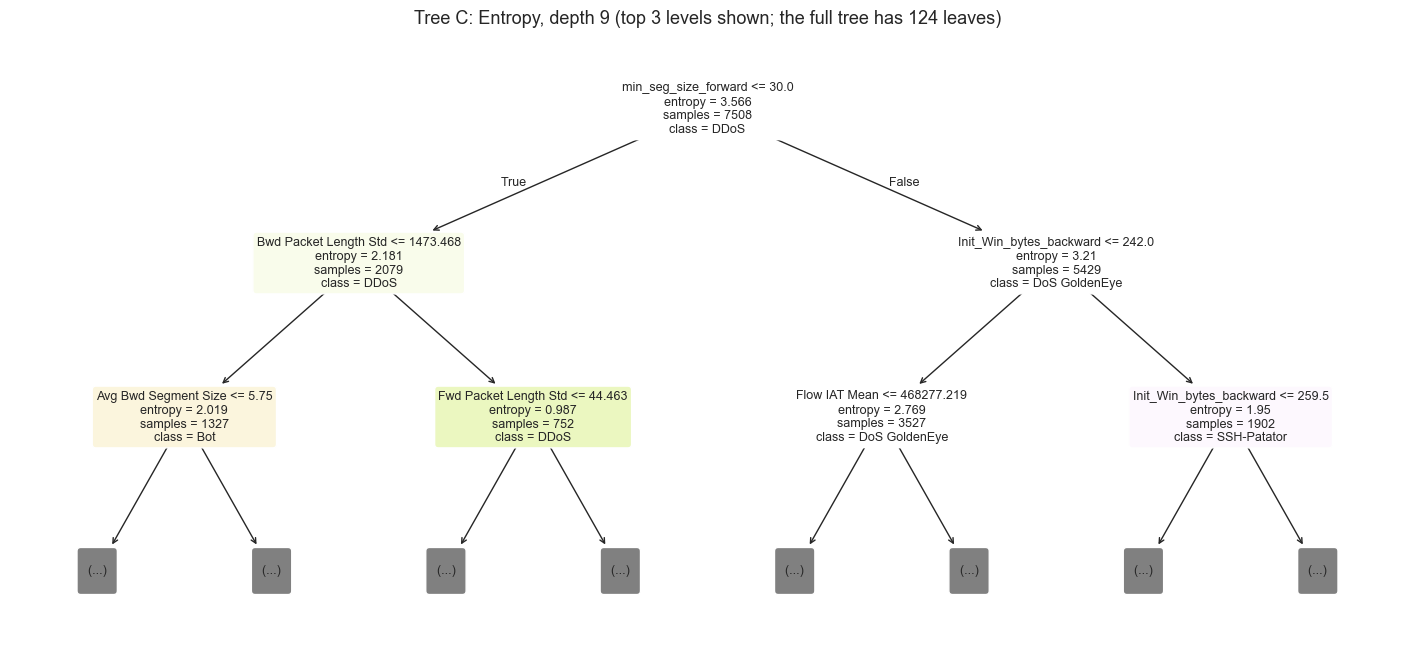

In [10]:
name_c = list(trees)[2]
draw_tree(tree_c, f"Tree {name_c} (top 3 levels shown; the full tree has {tree_c.get_n_leaves()} leaves)",
          "figures/dt-05-tree-tuned.png", max_depth=2, size=(18, 8))

In [11]:
print("Tree A as text rules:")
print(export_text(tree_a, feature_names=features, max_depth=3))

Tree A as text rules:
|--- Bwd Header Length <= 986.00
|   |--- min_seg_size_forward <= 30.00
|   |   |--- Bwd IAT Min <= 531.50
|   |   |   |--- class: DDoS
|   |   |--- Bwd IAT Min >  531.50
|   |   |   |--- class: Bot
|   |--- min_seg_size_forward >  30.00
|   |   |--- Init_Win_bytes_backward <= 1146.00
|   |   |   |--- class: DoS GoldenEye
|   |   |--- Init_Win_bytes_backward >  1146.00
|   |   |   |--- class: Web Attack - Brute Force
|--- Bwd Header Length >  986.00
|   |--- Flow Bytes/s <= 741.54
|   |   |--- Fwd IAT Mean <= 1267123.00
|   |   |   |--- class: SSH-Patator
|   |   |--- Fwd IAT Mean >  1267123.00
|   |   |   |--- class: BENIGN
|   |--- Flow Bytes/s >  741.54
|   |   |--- Max Packet Length <= 1111.00
|   |   |   |--- class: Web Attack - Brute Force
|   |   |--- Max Packet Length >  1111.00
|   |   |   |--- class: BENIGN



## 5. Confusion Matrix and Accuracy for Tree C

Tree C testing accuracy: 0.925


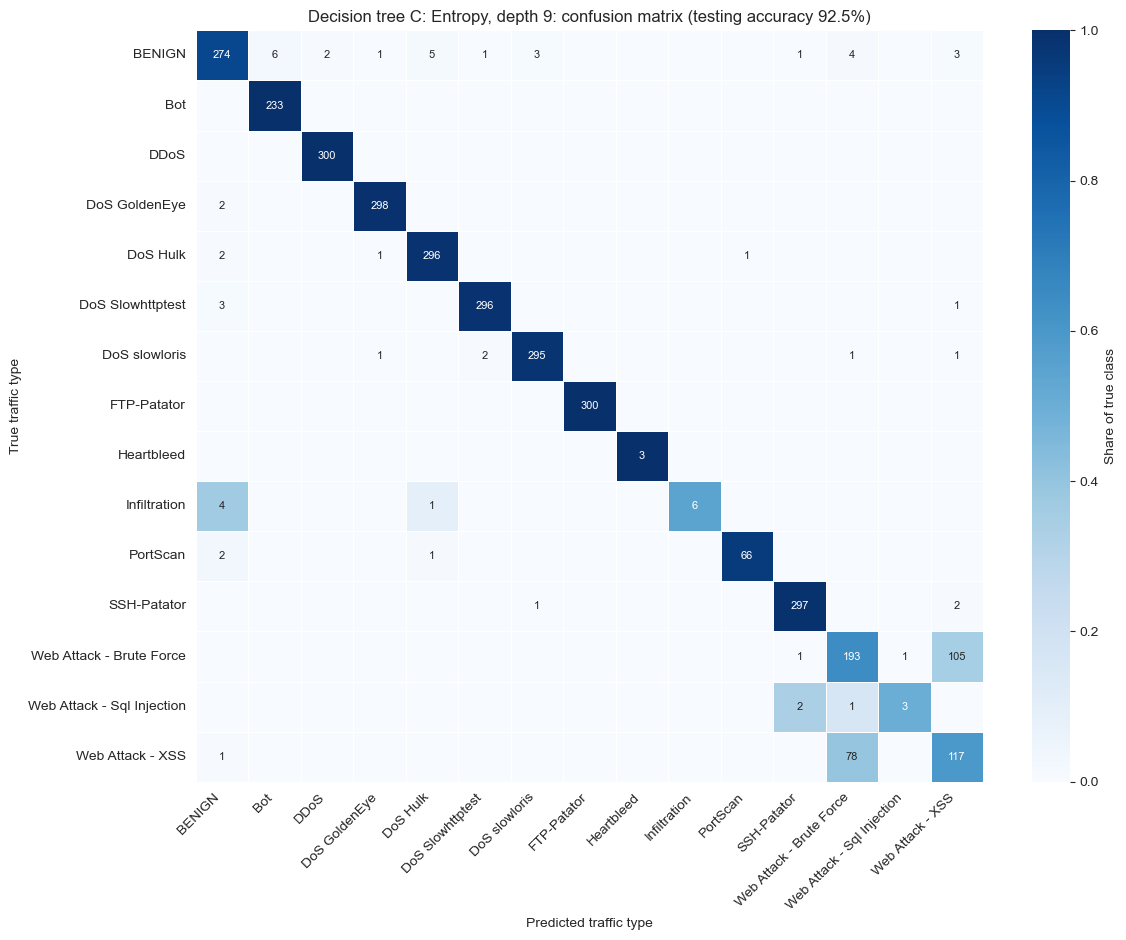

In [12]:
pred_c = tree_c.predict(X_test)
acc_c = accuracy_score(y_test, pred_c)
print(f"Tree C testing accuracy: {acc_c:.3f}")

cm = confusion_matrix(y_test, pred_c, labels=classes)
share = cm / cm.sum(axis=1, keepdims=True)
annot = np.where(cm == 0, "", cm.astype(str))

fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(share, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1,
            xticklabels=classes, yticklabels=classes, linewidths=0.4, linecolor="white",
            cbar_kws={"label": "Share of true class"}, annot_kws={"fontsize": 8}, ax=ax)
ax.set_xlabel("Predicted traffic type")
ax.set_ylabel("True traffic type")
ax.set_title(f"Decision tree {name_c}: confusion matrix (testing accuracy {acc_c:.1%})")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("figures/dt-06-confusion-matrix.png", dpi=160, bbox_inches="tight")
plt.show()

In [13]:
report = pd.DataFrame(classification_report(y_test, pred_c, output_dict=True, zero_division=0)).T
report = report.loc[classes + ["macro avg", "weighted avg"], ["precision", "recall", "f1-score", "support"]]
report.round(3)

,precision,recall,f1-score,support
BENIGN,0.951,0.913,0.932,300.0
Bot,0.975,1.000,0.987,233.0
DDoS,0.993,1.000,0.997,300.0
DoS GoldenEye,0.990,0.993,0.992,300.0
DoS Hulk,0.977,0.987,0.982,300.0
DoS Slowhttptest,0.990,0.987,0.988,300.0
DoS slowloris,0.987,0.983,0.985,300.0
FTP-Patator,1.000,1.000,1.000,300.0
Heartbleed,1.000,1.000,1.000,3.0
Infiltration,1.000,0.545,0.706,11.0


In [14]:
benign = (y_test == "BENIGN").values
flagged = (pred_c != "BENIGN")
print(f"False alarm rate (BENIGN flagged as attack): {flagged[benign].mean():.3f}")
print(f"Detection rate (attack flagged as some attack): {flagged[~benign].mean():.3f}")

False alarm rate (BENIGN flagged as attack): 0.087
Detection rate (attack flagged as some attack): 0.995


## 6. Feature Importance

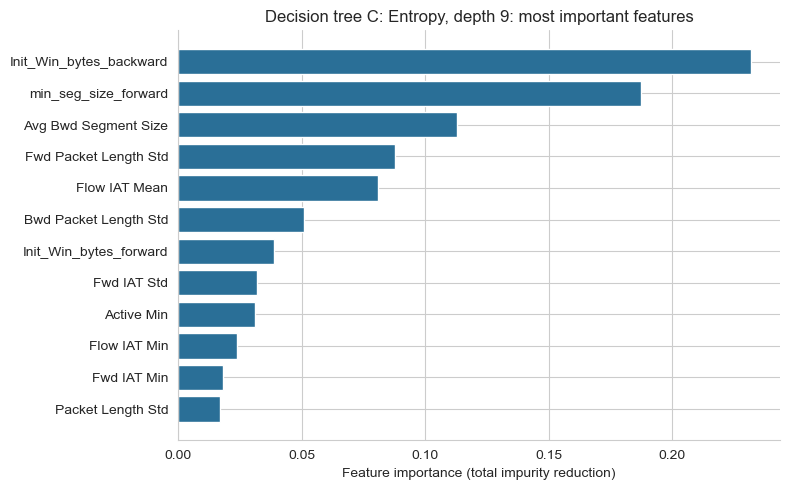

,importance
Init_Win_bytes_backward,0.232
min_seg_size_forward,0.187
Avg Bwd Segment Size,0.113
Fwd Packet Length Std,0.088
Flow IAT Mean,0.081
Bwd Packet Length Std,0.051
Init_Win_bytes_forward,0.039
Fwd IAT Std,0.032
Active Min,0.031
Flow IAT Min,0.024


In [15]:
importance = pd.Series(tree_c.feature_importances_, index=features).sort_values(ascending=False)
top = importance.head(12).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color="#2a6f97")
ax.set_xlabel("Feature importance (total impurity reduction)")
ax.set_title(f"Decision tree {name_c}: most important features")
plt.tight_layout()
plt.savefig("figures/dt-07-feature-importance.png", dpi=160, bbox_inches="tight")
plt.show()

importance.head(12).round(3).to_frame("importance")

## 7. Different Trees on the Same Data

Five trees are fitted in sequence. The root feature of each tree is removed before the next is fitted.

In [16]:
remaining = list(features)
rows = []
for step in range(5):
    t = DecisionTreeClassifier(criterion="gini", max_depth=8, random_state=SEED).fit(X_train[remaining], y_train)
    root = remaining[t.tree_.feature[0]]
    rows.append({"Tree": step + 1,
                 "Features available": len(remaining),
                 "Root feature": root,
                 "Root threshold": round(float(t.tree_.threshold[0]), 2),
                 "Leaves": t.get_n_leaves(),
                 "Testing accuracy": round(t.score(X_test[remaining], y_test), 3)})
    remaining.remove(root)
pd.DataFrame(rows).set_index("Tree")

,Features available,Root feature,Root threshold,Leaves,Testing accuracy
Tree,,,,,
1,65,Bwd Header Length,986.0,77,0.887
2,64,Subflow Bwd Packets,30.5,76,0.889
3,63,Total Backward Packets,30.5,76,0.889
4,62,Fwd Packet Length Max,638.0,87,0.885
5,61,act_data_pkt_fwd,15.5,77,0.887
